In [1]:
!pip install rasterio matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   -- ------------------------------------- 1.6/31.4 MB 5.3 MB/s eta 0:00:06
   --- ------------------------------------ 2.4/31.4 MB 4.6 MB/s eta 0:00:07
   ---- ----------------------------------- 3.1/31.4 MB 4.4 MB/s eta 0:00:07
   ----- ---------------------------------- 3.9/31.4 MB 4.3 MB/s eta 0:00:07
   ------ --------------------------------- 4.7/31.4 MB 4.2 MB/s eta 0:00:07
   ------- -------------------------------- 5.8/31.4 MB 4.1 MB/s eta 0:00:07
   -------- ------------------------------- 6.6/31.4 MB 4.1 MB/s eta 0:00:07
   --------- ------------------------------ 7.3/31.4 MB 4.1 MB/s eta 0:00:06
   ---------- ----------------------------- 8.1/31.4 MB 4.1 MB/s eta 0:00:06
   ----------- ---------------------------- 8.9/31.4 MB 4.0 MB/s eta 0:00:06
   ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

In [2]:
s1_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand"
label_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = os.path.join(s1_folder, image_name)
label_path = os.path.join(label_folder, label_name)

len(image_name)

25

In [3]:
### dataset info
with rasterio.open(image_path) as src:
    print("file:",image_name[0])
    print("width:",src.width)
    print("height:",src.height)
    print("no.of bands:",src.count)
    print("data type:",src.dtypes)
    
    
    image = src.read()
    print("Image shape:", image.shape)
    print("Minimum value:", image.min())
    print("Maximum value:", image.max())
    for i in range(src.count):
        print(f"Band {i+1}:")
        print("  Min:", image[i].min())
        print("  Max:", image[i].max())
        print("  Mean:", image[i].mean())

file: B
width: 512
height: 512
no.of bands: 2
data type: ('float32', 'float32')
Image shape: (2, 512, 512)
Minimum value: nan
Maximum value: nan
Band 1:
  Min: nan
  Max: nan
  Mean: nan
Band 2:
  Min: nan
  Max: nan
  Mean: nan


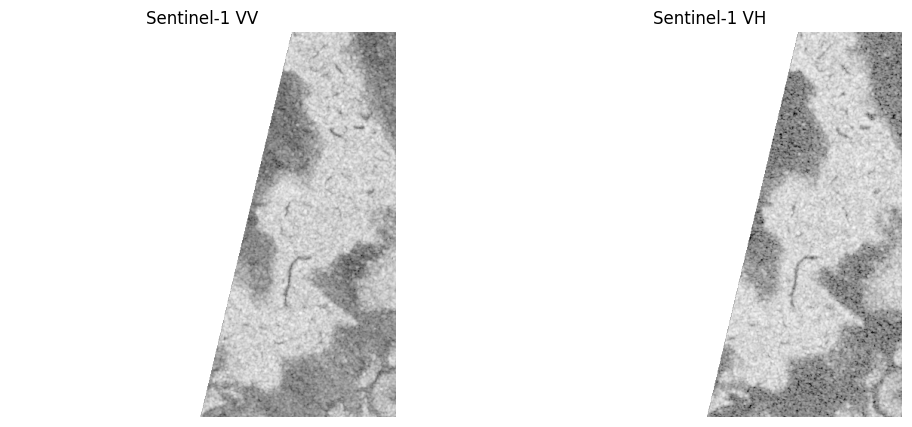

In [4]:
### vv and vh representation
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    vv = src.read(1)
    vh = src.read(2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.title("Sentinel-1 VV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vh, cmap="gray")
plt.title("Sentinel-1 VH")
plt.axis("off")

plt.show()

In [5]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label shape:", label.shape)
print("Label data type:", label.dtype)
print("Unique label values:", np.unique(label))

Label shape: (512, 512)
Label data type: int16
Unique label values: [-1  0  1]


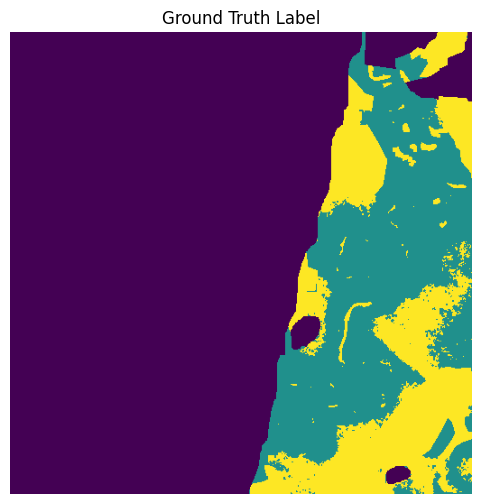

In [6]:
### Ground-Truth Label Inspection
plt.figure(figsize=(6, 6))

plt.imshow(label)
plt.title("Ground Truth Label")
plt.axis("off")

plt.show()

In [7]:
import os
import rasterio
import numpy as np

jrc_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\JRCWaterHand"

jrc_name = "Bolivia_129334_JRCWaterHand.tif"
jrc_path = os.path.join(jrc_folder, jrc_name)

with rasterio.open(jrc_path) as src:
    jrc = src.read(1)

print("JRC shape:", jrc.shape)
print("JRC pixels with permanent water:", np.sum(jrc == 1))
print("JRC water percentage:", np.sum(jrc == 1) / jrc.size * 100)

JRC shape: (512, 512)
JRC pixels with permanent water: 4152
JRC water percentage: 1.5838623046875


In [8]:
import os
import rasterio
import numpy as np

jrc_files = os.listdir(jrc_folder)

print("Total JRC files:", len(jrc_files))

for file in jrc_files[:10]:
    path = os.path.join(jrc_folder, file)
    with rasterio.open(path) as src:
        data = src.read(1)
        print(file, np.unique(data))

Total JRC files: 446
Bolivia_103757_JRCWaterHand.tif [0]
Bolivia_129334_JRCWaterHand.tif [0 1]
Bolivia_195474_JRCWaterHand.tif [0]
Bolivia_23014_JRCWaterHand.tif [0 1]
Bolivia_233925_JRCWaterHand.tif [0]
Bolivia_242570_JRCWaterHand.tif [0]
Bolivia_290290_JRCWaterHand.tif [0 1]
Bolivia_294583_JRCWaterHand.tif [0 1]
Bolivia_312675_JRCWaterHand.tif [0]
Bolivia_314919_JRCWaterHand.tif [0 1]


In [9]:
print("JRC unique values:", np.unique(jrc))
print("Number of pixels:", jrc.size)
print("Number of JRC water pixels:", np.sum(jrc == 1))

JRC unique values: [0 1]
Number of pixels: 262144
Number of JRC water pixels: 4152


In [10]:
label_name = "Bolivia_129334_LabelHand.tif"
label_path = os.path.join(label_folder, label_name)

with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label values:", np.unique(label))

print("Label water pixels:", np.sum(label == 1))
print("Permanent water pixels:", np.sum(jrc == 1))

overlap = np.sum((label == 1) & (jrc == 1))

print("Water + permanent water overlap:", overlap)

Label values: [-1  0  1]
Label water pixels: 156643
Permanent water pixels: 4152
Water + permanent water overlap: 3994


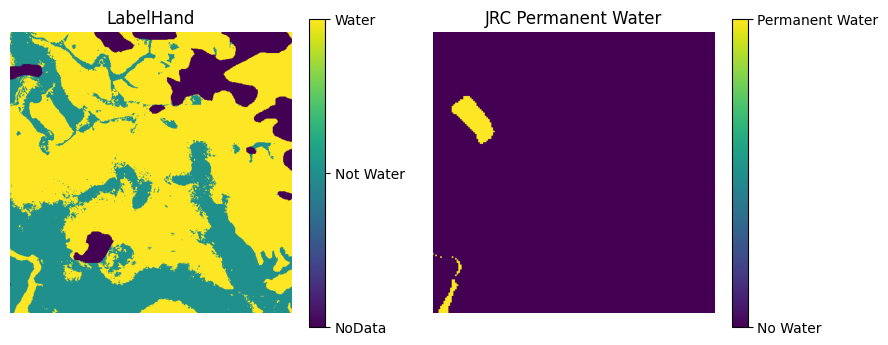

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(label)
plt.title("LabelHand")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([-1, 0, 1])
c.set_ticklabels(["NoData", "Not Water", "Water"])

plt.subplot(1, 2, 2)
plt.imshow(jrc)
plt.title("JRC Permanent Water")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([0, 1])
c.set_ticklabels(["No Water", "Permanent Water"])

plt.show()

In [12]:
# label == 0 → Land 
# label == 1 → temporarily called Flooded Land (2) 
# label == 1 AND jrc == 1 → changed to Permanent Water (1) 

three_class = np.zeros_like(label, dtype=np.uint8)

three_class[label == 1] = 2
three_class[(label == 1) & (jrc == 1)] = 1

In [13]:
# ignore classes with -1
three_class[label == -1] = 255

print("Final values:", np.unique(three_class))

Final values: [  0   1   2 255]


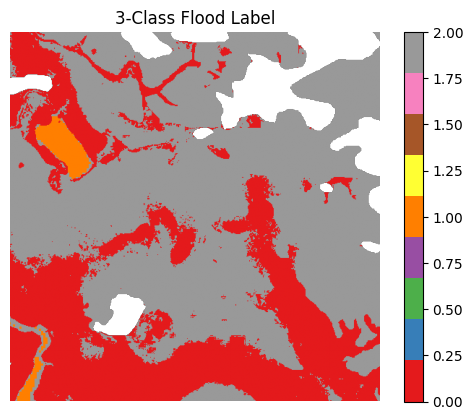

In [14]:
plt.imshow(np.ma.masked_equal(three_class, 255), cmap="Set1", vmin=0, vmax=2)
plt.title("3-Class Flood Label")
plt.colorbar()
plt.axis("off")
plt.show()

In [15]:
for value in [0, 1, 2, 255]:
    print(value, ":", np.sum(three_class == value))

0 : 81171
1 : 3994
2 : 152649
255 : 24330


In [16]:
total = np.sum(three_class != 255)

for value, name in [(0, "Land"), (1, "Permanent Water"), (2, "Flooded Land")]:
    count = np.sum(three_class == value)
    print(name, ":", count, "pixels,", round(count / total * 100, 2), "%")

Land : 81171 pixels, 34.13 %
Permanent Water : 3994 pixels, 1.68 %
Flooded Land : 152649 pixels, 64.19 %


In [17]:
print("VV - valid pixels:", np.sum(np.isfinite(vv)))
print("VV - total pixels:", vv.size)

print("VH - valid pixels:", np.sum(np.isfinite(vh)))
print("VH - total pixels:", vh.size)

print("\nVV - NaN pixels:", np.sum(np.isnan(vv)))
print("VH - NaN pixels:", np.sum(np.isnan(vh)))

VV - valid pixels: 101623
VV - total pixels: 262144
VH - valid pixels: 101623
VH - total pixels: 262144

VV - NaN pixels: 160521
VH - NaN pixels: 160521


In [18]:
### preprocessing
print("VV NaN pixels:", np.isnan(vv).sum())
print("VH NaN pixels:", np.isnan(vh).sum())

VV NaN pixels: 160521
VH NaN pixels: 160521


In [19]:
vv.shape

(512, 512)

In [20]:
print("Label NoData:", np.sum(label == -1))
print("S1 VV NoData:", np.isnan(vv).sum())

Label NoData: 24330
S1 VV NoData: 160521


In [52]:
nodata_mask = np.isnan(vv) | np.isnan(vh) | (label == -1)

print("Total pixels to ignore:", nodata_mask.sum())

Total pixels to ignore: 173901


In [53]:
vv_min, vv_max = np.nanmin(vv), np.nanmax(vv)
vh_min, vh_max = np.nanmin(vh), np.nanmax(vh)

vv_norm = (vv - vv_min) / (vv_max - vv_min)
vh_norm = (vh - vh_min) / (vh_max - vh_min)

# minimum value of an array while ignoring any NaN
print("VV range:", np.nanmin(vv_norm), np.nanmax(vv_norm))
print("VH range:", np.nanmin(vh_norm), np.nanmax(vh_norm))

VV range: 0.0 1.0
VH range: 0.0 1.0


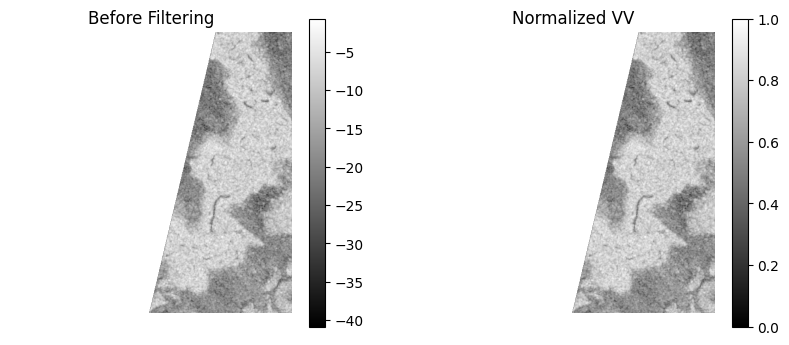

In [54]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.colorbar()
plt.title("Before Filtering")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vv_norm, cmap="gray")
plt.title("Normalized VV")
plt.colorbar()
plt.axis("off")
plt.show()

In [55]:
vv_temp = np.nan_to_num(vv_norm, nan=0)
vh_temp = np.nan_to_num(vh_norm, nan=0)

In [56]:
from scipy.ndimage import median_filter

vv_filtered = median_filter(vv_temp, size=3)
vh_filtered = median_filter(vh_temp, size=3)

print("VV filtering done")
print("VH filtering done")

VV filtering done
VH filtering done


In [57]:
vv_filtered[nodata_mask] = np.nan
vh_filtered[nodata_mask] = np.nan

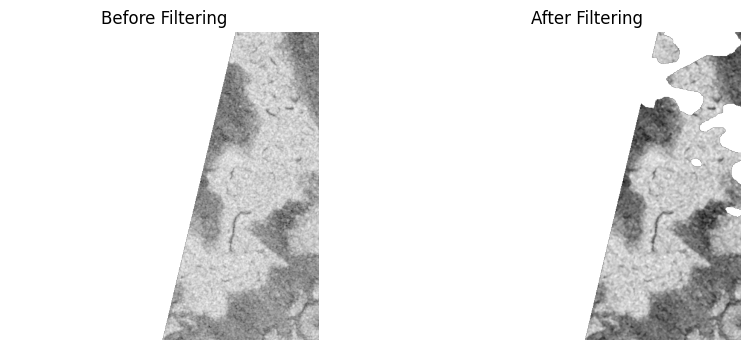

In [58]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(vv_norm, cmap="gray")
plt.title("Before Filtering")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vv_filtered, cmap="gray")
plt.title("After Filtering")
plt.axis("off")

plt.show()

In [51]:
s1_input = np.stack([vv_filtered, vh_filtered], axis=0)
print("S1 input shape:", s1_input.shape)

S1 input shape: (2, 512, 512)
